In [ ]:
d_coeff = 1
c_coeff = 1
num_iterations = 5
parameters = (d_coeff, c_coeff, num_iterations)

In [ ]:
k_10 = 1

In [ ]:
import numpy as np
from scipy.signal import convolve2d

def run_spin_simulation(
    initial_array_2d,
    kernel_dmx,
    parameters
):

    kernel_dmy = np.transpose(kernel_dmx)
    # Dynamically determine kernel_dmz shape from kernel_dmx
    kernel_dmz = np.zeros(kernel_dmx.shape)
    kernel_HJ = kernel_dmx * kernel_dmx + kernel_dmy * kernel_dmy

    d_coeff, c_coeff, num_iterations = parameters

    # Initialize S fields
    Sx = np.zeros_like(initial_array_2d)
    Sy = np.zeros_like(initial_array_2d)
    Sz = initial_array_2d.copy() # Use a copy to avoid modifying the original input

    # Initialize fixed HOx, HOy, HOz values based on the initial S fields
    HOx_fixed = Sx.copy()
    HOy_fixed = Sy.copy()
    HOz_fixed = Sz.copy()

    # Initialize lists to store energy values
    et_values = []
    ej_values = []

    # Main simulation loop
    for i in range(num_iterations):
        # a. Calculate HJx, HJy, and HJz by convolving Sx, Sy, and Sz with kernel_HJ
        HJx = convolve2d(Sx, kernel_HJ, mode='same', boundary='wrap')
        HJy = convolve2d(Sy, kernel_HJ, mode='same', boundary='wrap')
        HJz = convolve2d(Sz, kernel_HJ, mode='same', boundary='wrap')

        # b. Calculate HDx, HDy, and HDz by convolving Sz with derivative kernels
        HDx = convolve2d(Sz, kernel_dmx, mode='same', boundary='wrap')
        HDy = convolve2d(Sz, kernel_dmy, mode='same', boundary='wrap')
        HDz = convolve2d(Sz, kernel_dmz, mode='same', boundary='wrap')

        # d, e, f. Calculate HTx, HTy, and HTz
        HTx = HJx + d_coeff * HDx + c_coeff * HOx_fixed
        HTy = HJy + d_coeff * HDy + c_coeff * HOy_fixed
        HTz = HJz + d_coeff * HDz + c_coeff * HOz_fixed

        # g. Calculate the magnitude of the HT vector at each point
        magnitudes_HT = np.sqrt(HTx**2 + HTy**2 + HTz**2)

        # h. Create a boolean mask to identify points where magnitudes are zero
        zero_magnitudes_HT_mask = (magnitudes_HT == 0)

        # i. Create a reciprocal of magnitudes, handling division by zero
        inv_magnitudes_HT = np.where(zero_magnitudes_HT_mask, 0, 1 / magnitudes_HT)

        # j. Normalize HT components to get the new S components
        Sx_new = HTx * inv_magnitudes_HT
        Sy_new = HTy * inv_magnitudes_HT
        Sz_new = HTz * inv_magnitudes_HT

        # Calculate UJ = -HJ . S
        UJ = -(HJx * Sx_new + HJy * Sy_new + HJz * Sz_new)


        # Calculate UD = -d_coeff * (HD . S)
        UD = -d_coeff * (HDx * Sx_new + HDy * Sy_new + HDz * Sz_new)

        # Calculate UO = -c_coeff * (HO . S), using the fixed HO values
        UO = -c_coeff * (HOx_fixed * Sx_new + HOy_fixed * Sy_new + HOz_fixed * Sz_new)

        UT = UJ + UD + UO

        # Calculate and store average energy values
        ET = UT
        et_values.append(np.average(ET))
        EJ = UJ + np.sum(kernel_HJ)
        ej_values.append(np.sum(EJ))

        # k. Update Sx, Sy, and Sz for the next iteration
        Sx = Sx_new
        Sy = Sy_new
        Sz = Sz_new

    Tx = (HJx * Sx_new - HJy * Sy_new)
    Ty = (HJx * Sy_new + HJy * Sx_new)

    magnitude = np.sqrt(Tx**2 + Ty**2)
    angle = -np.pi/2+np.arctan2(Ty, Tx)/2 # in radians

    OrX = magnitude * np.cos(angle)
    OrY = magnitude * np.sin(angle)

    txSum = np.sum(Tx)
    tySum = np.sum(Ty)

    tiltingAmount = np.sqrt(txSum**2 + tySum**2)
    tiltingAngle = 45-90/np.pi*np.arctan2(-np.array(txSum), -np.array(tySum))
    totalAmount = np.sum(magnitude)

    return totalAmount, tiltingAmount, tiltingAngle, np.stack([Sx, Sy, Sz], axis = -1), ET, EJ, np.stack([Tx, Ty], axis = -1), np.stack([OrX, OrY], axis = -1), magnitude, angle, et_values, ej_values

In [ ]:
import numpy as np

def generate_rounded_rotated_rectangle(
    size,
    center_x,
    center_y,
    half_long_side,
    half_short_side,
    angle_degrees,
    corner_radius
):
    """
    Generates a 2D NumPy array representing a rectangle with rounded corners,
    rotated by the given angle.

    Args:
        size (int): The dimension of the square output array (size x size).
        center_x (float): The x-coordinate of the rectangle's center.
        center_y (float): The y-coordinate of the rectangle's center.
        half_long_side (float): Half the length of the longer side of the rectangle.
        half_short_side (float): Half the length of the shorter side of the rectangle.
        angle_degrees (float): The rotation angle of the rectangle in degrees.
        corner_radius (float): The radius of the rounded corners.

    Returns:
        np.ndarray: A 2D NumPy array of size x size, with 1 inside the rounded
                    rotated rectangle and -1 outside.
    """
    # Ensure corner_radius does not exceed half of the shorter side for valid geometry
    corner_radius = min(corner_radius, half_long_side, half_short_side)

    x_coords = np.linspace(-100, 100, size)
    y_coords = np.linspace(-100, 100, size)
    X, Y = np.meshgrid(x_coords, y_coords)

    translated_X = X - center_x
    translated_Y = Y - center_y

    angle_radians = np.deg2rad(angle_degrees)

    rotated_X = translated_X * np.cos(angle_radians) + translated_Y * np.sin(angle_radians)
    rotated_Y = -translated_X * np.sin(angle_radians) + translated_Y * np.cos(angle_radians)

    # Condition for the main body of the rectangle (excluding corners)
    inside_main_body = (
        (np.abs(rotated_X) <= (half_long_side - corner_radius)) & (np.abs(rotated_Y) <= half_short_side) |
        (np.abs(rotated_Y) <= (half_short_side - corner_radius)) & (np.abs(rotated_X) <= half_long_side)
    )

    # Conditions for the rounded corners
    # Calculate distances from the center of the quarter circles
    rx_corner_dist = np.abs(rotated_X) - (half_long_side - corner_radius)
    ry_corner_dist = np.abs(rotated_Y) - (half_short_side - corner_radius)

    inside_rounded_corners = (
        (rx_corner_dist > 0) & (ry_corner_dist > 0) &
        (rx_corner_dist**2 + ry_corner_dist**2 <= corner_radius**2)
    )

    # Combine conditions
    inside_rectangle = inside_main_body | inside_rounded_corners

    rectangle_array = np.full((size, size), -1.0)
    rectangle_array[inside_rectangle] = 1.0

    return rectangle_array

print("Function 'generate_rounded_rotated_rectangle' defined.")

Function 'generate_rounded_rotated_rectangle' defined.


In [ ]:
size = 200
center_x = 0
center_y = 0
half_long_side = 50
half_short_side = 25
corner_radius = 25

In [ ]:
trainingSet = []
rotation_angles = np.arange(0, 90.2, 0.2)
for angle in rotation_angles:
  trainingSet.append(generate_rounded_rotated_rectangle(size=size, center_x=center_x, center_y=center_y, half_long_side=half_long_side, half_short_side=half_short_side, angle_degrees = angle, corner_radius = corner_radius))

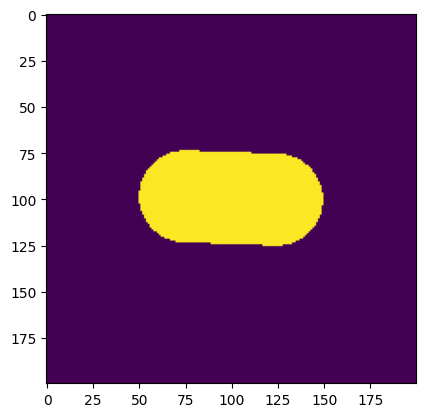

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(trainingSet[10])

In [ ]:
basic_kernel_dmx = np.array([[0.0,0,0.0],[1,0,-1],[0.0,0,0.0]])

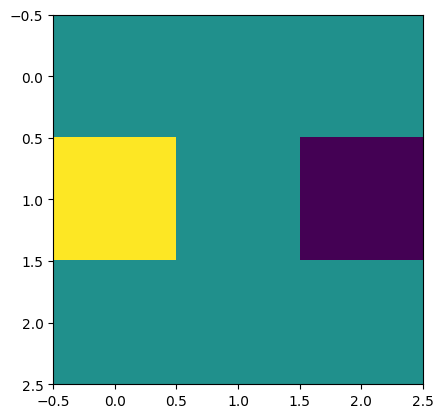

In [ ]:
plt.imshow(basic_kernel_dmx)

In [ ]:
finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=trainingSet[10],
        kernel_dmx = basic_kernel_dmx,
        parameters = parameters
    )

In [ ]:
finalTot, finalTSum, finalTAngle

(np.float64(1855.4249151109486),
 np.float64(693.6838007143491),
 np.float64(2.0783718248429466))

In [ ]:
answer= [(50*2+50*np.pi), 100]
print(answer)

[257.0796326794897, 100]


In [ ]:
[finalTot/(answer[0]), finalTSum/(answer[1])]

[np.float64(7.217315879022485), np.float64(6.936838007143491)]

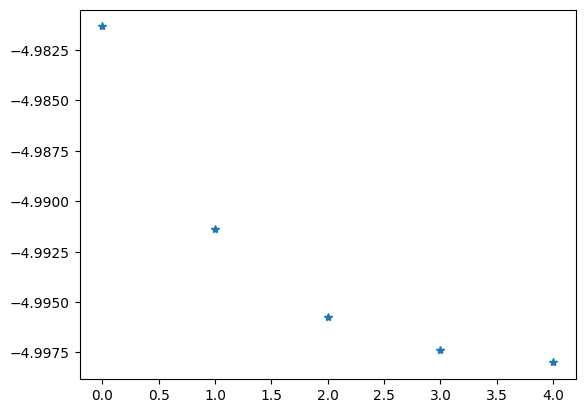

In [ ]:
plt.plot(et_values,'*')

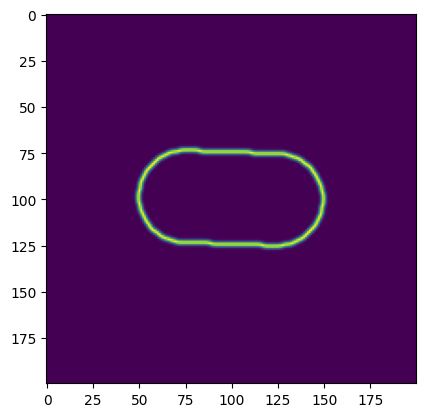

In [ ]:
plt.imshow(Omag)

In [ ]:
tt_results = []
td_results = []
theta_results = []

for i, rotated_array in enumerate(trainingSet):
    # Unpack the 8 return values from run_spin_simulation
    finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=rotated_array,
        kernel_dmx = basic_kernel_dmx,
        parameters = parameters
    )

    #print(f"Final Energy Sum: {finalTSum}")
    #print(f"Final Angle: {finalTAngle}")

    # The function now returns aggregated values for EJ, OX, OY, so no need for np.sum here.
    tt_results.append(finalTot)
    td_results.append(finalTSum)
    theta_results.append(finalTAngle)



7.311584023873087
0.007444619627961385
7.24476627317179
0.022153742513183482
-2.9619076346540763e-15
0.875759667935984


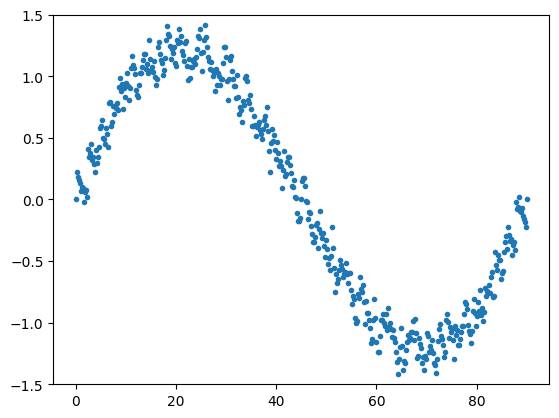

In [ ]:
print(np.average(tt_results)/(answer[0]))
print(np.std(tt_results)/np.average(tt_results))
print(np.average(td_results)/(answer[1]))
print(np.std(td_results)/np.average(td_results))
import matplotlib.pyplot as plt

#plt.plot(rotation_angles, rotation_angles)
plt.ylim(-1.5,1.5)
plt.plot(rotation_angles, theta_results-rotation_angles, '.')
thetaError = theta_results-rotation_angles
print(np.average(thetaError))
print(np.std(thetaError))

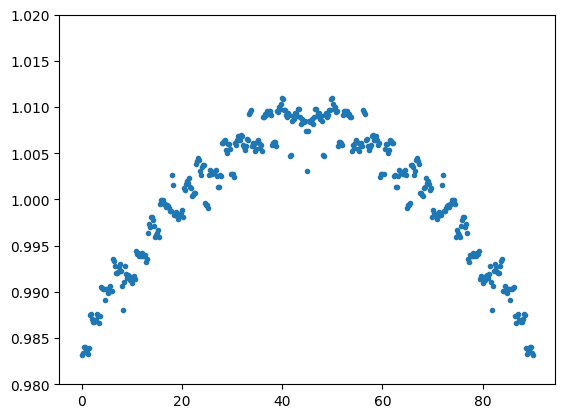

In [ ]:
plt.ylim(0.98, 1.02)
plt.plot(rotation_angles, tt_results/np.average(tt_results), '.')


In [ ]:
preset_kernel_dmx = np.array([[0.5,0,-0.5],[1,0,-1],[0.5,0,-0.5]]) #소버필터

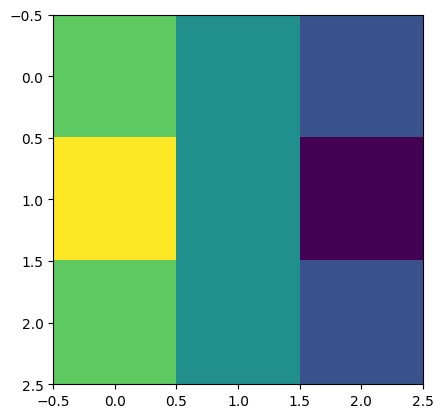

In [ ]:
plt.imshow(preset_kernel_dmx)

In [ ]:
finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=trainingSet[10],
        kernel_dmx = preset_kernel_dmx,
        parameters = parameters
    )

In [ ]:
finalTot, finalTSum, finalTAngle

(np.float64(4050.162997391197),
 np.float64(1553.9064393574083),
 np.float64(1.9135741563123787))

In [ ]:
answer= [(50*2+50*np.pi), 100]
print(answer)

[257.0796326794897, 100]


In [ ]:
[finalTot/(answer[0]), finalTSum/(answer[1])]

[np.float64(15.754507485393365), np.float64(15.539064393574083)]

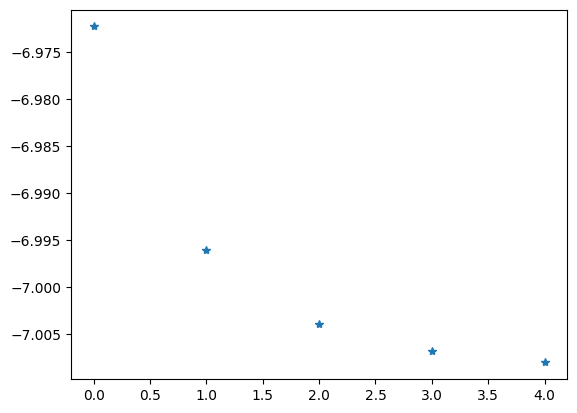

In [ ]:
plt.plot(et_values,'*')

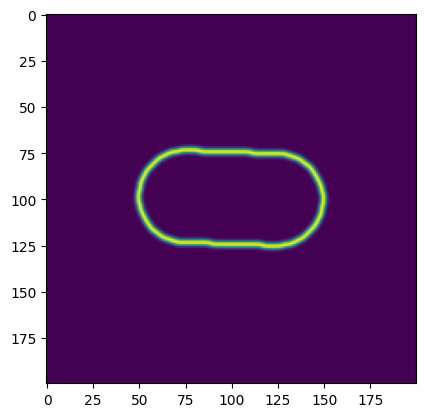

In [ ]:
plt.imshow(Omag)

In [ ]:
tt_results = []
td_results = []
theta_results = []

for i, rotated_array in enumerate(trainingSet):
    # Unpack the 8 return values from run_spin_simulation
    finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=rotated_array,
        kernel_dmx = preset_kernel_dmx,
        parameters = parameters
    )

    #print(f"Final Energy Sum: {finalTSum}")
    #print(f"Final Angle: {finalTAngle}")

    # The function now returns aggregated values for EJ, OX, OY, so no need for np.sum here.
    tt_results.append(finalTot)
    td_results.append(finalTSum)
    theta_results.append(finalTAngle)



15.772315206163055
0.0012607046055389353
15.720843031366963
0.0057488016897099484
-2.694075561307697e-15
0.19276651794387928


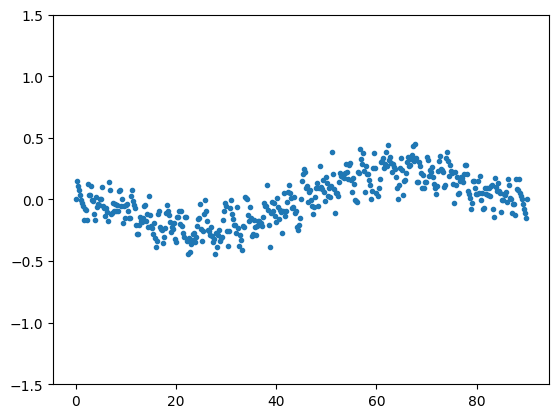

In [ ]:
print(np.average(tt_results)/(answer[0]))
print(np.std(tt_results)/np.average(tt_results))
print(np.average(td_results)/(answer[1]))
print(np.std(td_results)/np.average(td_results))
import matplotlib.pyplot as plt

#plt.plot(rotation_angles, rotation_angles)
plt.ylim(-1.5,1.5)
plt.plot(rotation_angles, theta_results-rotation_angles, '.')
thetaError = theta_results-rotation_angles
print(np.average(thetaError))
print(np.std(thetaError))

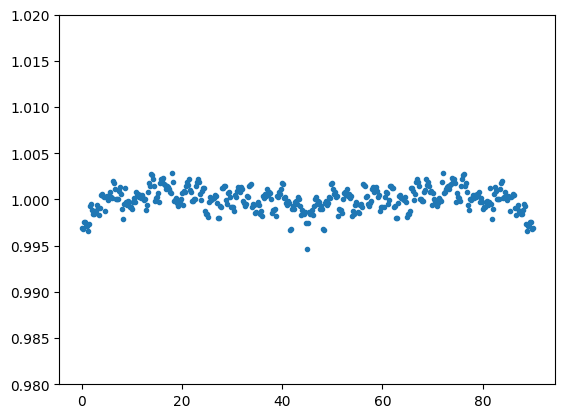

In [ ]:
plt.ylim(0.98, 1.02)
plt.plot(rotation_angles, tt_results/np.average(tt_results), '.')


In [ ]:
def objective_function(k_11):
    k_10 = 1

    # 1. Inside objective_function, construct the kernel_dmx matrix

    # 2. Inside objective_function, construct the kernel_dmx matrix

    kernel_dmx = np.array(
        [[k_11, 0, -k_11],
         [k_10, 0, -k_10],
         [k_11, 0, -k_11]]
    )

    # 3. Initialize empty lists
    tt_results = []
    td_results = []
    theta_results = []

    # 4. Iterate through rotated_rectangle_arrays and rotation_angles
    for i, rotated_array in enumerate(trainingSet):
        # a. Call run_spin_simulation
        # The function run_spin_simulation returns 12 values, but we only need a few for the metrics
        finalTt, finalTd, finalTAngle, _, _, _, _, _, _, _, _, _ = run_spin_simulation(
            initial_array_2d=rotated_array,
            kernel_dmx=kernel_dmx,
            parameters=parameters
        )

        # b. Append the results
        tt_results.append(finalTt)
        td_results.append(finalTd)
        theta_results.append(finalTAngle)

    # 5. Calculate thetaError
    thetaError = np.array(theta_results) - rotation_angles

    # 6. Calculate the four target metrics:
    # a. metric_ta
    metric_tt = np.average(tt_results)
    metric_td = np.average(td_results)
    metric_ratio = metric_tt / metric_td * answer[1] / answer[0]

    metric_tt_std_avg = np.std(tt_results) / np.average(tt_results)

    metric_td_std_avg = np.std(td_results) / np.average(td_results)

    # c. metric_theta_avg_error
    metric_theta_avg_error = np.average(thetaError)

    # d. metric_theta_std_error
    metric_theta_std_error = np.std(thetaError)

    # 7. Calculate the combined scalar cost
    cost = (metric_ratio - 1)**2 + 100*(metric_tt_std_avg**2 + metric_td_std_avg**2) + 10*( metric_theta_avg_error**2 + metric_theta_std_error**2 )
    #cost = metric_tt_std_avg**2

    # 8. Return the calculated cost
    return cost

print("Objective function 'objective_function' defined.")

Objective function 'objective_function' defined.


In [ ]:
from scipy.optimize import minimize

# 1. Define an initial guess for k_11
initial_guess = [0.5] # Original value, now correctly treated as a single parameter in an array

# 2. Define bounds for k_11
bounds = [
    (0., 1) # k_11: must be positive, reasonable upper bound
]

# 3. Define a wrapper function for objective_function to accept a single array argument
def objective_function_wrapper(params):
    # Extract the scalar value for k_11 from the params array
    k_11 = params[0]
    return objective_function(k_11)

# 4. Run the optimization
print("Starting optimization...")
result = minimize(
    objective_function_wrapper,
    initial_guess,
    bounds=bounds,
    method='L-BFGS-B' # A suitable method for bounded optimization
)

# 5. Extract optimized parameters
k_11 = result.x[0] # Extract the scalar from the result array
print(result)
print(result.x)

Starting optimization...
  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.13977424342061517
        x: [ 3.041e-01]
      nit: 6
      jac: [ 3.608e-08]
     nfev: 18
     njev: 9
 hess_inv: <1x1 LbfgsInvHessProduct with dtype=float64>
[0.30414468]


In [ ]:
kernel_dmx_3 = np.array([
            [k_11, 0, -k_11],
            [k_10, 0, -k_10],
            [k_11, 0, -k_11]
    ])

[[ 0.30414468  0.         -0.30414468]
 [ 1.          0.         -1.        ]
 [ 0.30414468  0.         -0.30414468]]


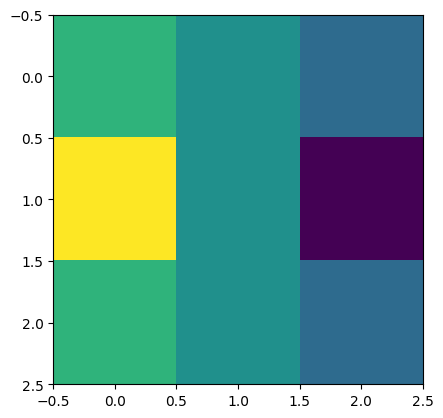

In [ ]:
print(kernel_dmx_3)
plt.imshow(kernel_dmx_3)

In [ ]:
tt_results = []
td_results = []
theta_results = []

for i, rotated_array in enumerate(trainingSet):
    # Unpack the 8 return values from run_spin_simulation
    finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=rotated_array,
        kernel_dmx = kernel_dmx_3,
        parameters = parameters
    )

    #print(f"Final Energy Sum: {finalTSum}")
    #print(f"Final Angle: {finalTAngle}")

    # The function now returns aggregated values for EJ, OX, OY, so no need for np.sum here.
    tt_results.append(finalTot)
    td_results.append(finalTSum)
    theta_results.append(finalTAngle)



11.215991650415196
0.003332072843882962
11.16275736743261
0.011628118738922378
-1.118592776917231e-15
0.1118570137944725


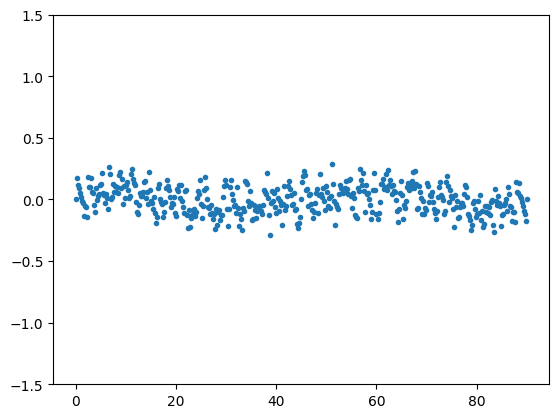

In [ ]:
print(np.average(tt_results)/(answer[0]))
print(np.std(tt_results)/np.average(tt_results))
print(np.average(td_results)/(answer[1]))
print(np.std(td_results)/np.average(td_results))
import matplotlib.pyplot as plt

#plt.plot(rotation_angles, rotation_angles)
plt.ylim(-1.5,1.5)
plt.plot(rotation_angles, theta_results-rotation_angles, '.')
thetaError = theta_results-rotation_angles
print(np.average(thetaError))
print(np.std(thetaError))

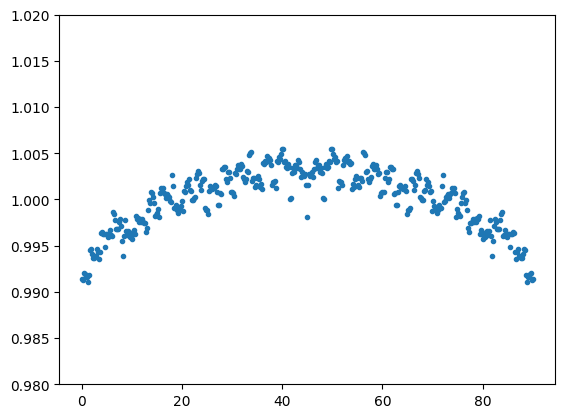

In [ ]:
plt.ylim(0.98, 1.02)
plt.plot(rotation_angles, tt_results/np.average(tt_results), '.')


In [ ]:
def objective_function(k_20, k_21, k_22, k_12):

    # 1. Inside objective_function, construct the kernel_dmx matrix

    # 2. Inside objective_function, construct the kernel_dmx matrix

    kernel_dmx = np.array(
        [
            [k_22, k_12, 0, -k_12, -k_22],
            [k_21, k_11, 0, -k_11, -k_21],
            [k_20, k_10, 0, -k_10, -k_20],
            [k_21, k_11, 0, -k_11, -k_21],
            [k_22, k_12, 0, -k_12, -k_22]
        ]
    )

    # 3. Initialize empty lists
    tt_results = []
    td_results = []
    theta_results = []

    # 4. Iterate through rotated_rectangle_arrays and rotation_angles
    for i, rotated_array in enumerate(trainingSet):
        # a. Call run_spin_simulation
        # The function run_spin_simulation returns 12 values, but we only need a few for the metrics
        finalTt, finalTd, finalTAngle, _, _, _, _, _, _, _, _, _ = run_spin_simulation(
            initial_array_2d=rotated_array,
            kernel_dmx=kernel_dmx,
            parameters=parameters
        )

        # b. Append the results
        tt_results.append(finalTt)
        td_results.append(finalTd)
        theta_results.append(finalTAngle)

    # 5. Calculate thetaError
    thetaError = np.array(theta_results) - rotation_angles

    # 6. Calculate the four target metrics:
    # a. metric_ta
    metric_tt = np.average(tt_results)
    metric_td = np.average(td_results)
    metric_ratio = metric_tt / metric_td * answer[1] / answer[0]

    metric_tt_std_avg = np.std(tt_results) / np.average(tt_results)

    metric_td_std_avg = np.std(td_results) / np.average(td_results)

    # c. metric_theta_avg_error
    metric_theta_avg_error = np.average(thetaError)

    # d. metric_theta_std_error
    metric_theta_std_error = np.std(thetaError)

    # 7. Calculate the combined scalar cost
    cost = (metric_ratio - 1)**2 + 100*(metric_tt_std_avg**2 + metric_td_std_avg**2) + 10*( metric_theta_avg_error**2 + metric_theta_std_error**2 )
    #cost = metric_tt_std_avg**2

    # 8. Return the calculated cost
    return cost

print("Objective function 'objective_function' defined.")

Objective function 'objective_function' defined.


In [ ]:
from scipy.optimize import minimize

# 1. Define an initial guess for a_d, d_d, and k_d
initial_guess = [0.2, 0.2, 0.2, 0.2] # Original values

# 2. Define bounds for a_d, d_d, and k_d
# Assuming these parameters should be non-negative and have reasonable upper limits
bounds = [  # a_d: must be positive, reasonable upper bound
    (-0.5, 1),   # k_d: must be positive, reasonable upper bound
    (-0.5, 1),
    (-0.5, 1),
    (-0.5, 1)
]

# 3. Define a wrapper function for objective_function to accept a single array argument
def objective_function_wrapper(params):
    k_20, k_21, k_22, k_12 = params
    return objective_function(k_20, k_21, k_22, k_12)

# 4. Run the optimization
print("Starting optimization...")
result = minimize(
    objective_function_wrapper,
    initial_guess,
    bounds=bounds,
    method='L-BFGS-B' # A suitable method for bounded optimization
)

# 5. Extract optimized parameters
k_20, k_21, k_22, k_12 = result.x
print(result)
print(result.x)

Starting optimization...
  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.10533458844524204
        x: [ 5.706e-01  3.369e-01  8.974e-02  9.205e-02]
      nit: 19
      jac: [ 8.007e-07  4.649e-07 -3.757e-06 -2.377e-06]
     nfev: 115
     njev: 23
 hess_inv: <4x4 LbfgsInvHessProduct with dtype=float64>
[0.57063894 0.33693168 0.08973684 0.09205035]


In [ ]:
kernel_dmx_5 = np.array(
        [
            [k_22, k_12, 0, -k_12, -k_22],
            [k_21, k_11, 0, -k_11, -k_21],
            [k_20, k_10, 0, -k_10, -k_20],
            [k_21, k_11, 0, -k_11, -k_21],
            [k_22, k_12, 0, -k_12, -k_22]
        ]
    )

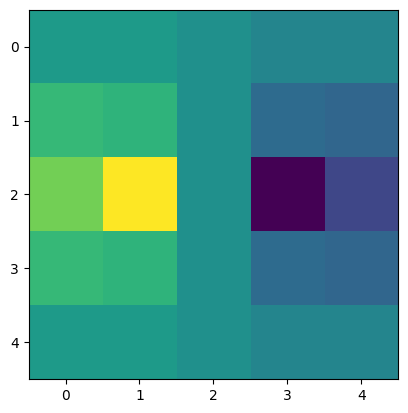

In [ ]:
plt.imshow(kernel_dmx_5)

In [ ]:
tt_results = []
td_results = []
theta_results = []

for i, rotated_array in enumerate(trainingSet):
    # Unpack the 8 return values from run_spin_simulation
    finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=rotated_array,
        kernel_dmx = kernel_dmx_5,
        parameters = parameters
    )

    #print(f"Final Energy Sum: {finalTSum}")
    #print(f"Final Angle: {finalTAngle}")

    # The function now returns aggregated values for EJ, OX, OY, so no need for np.sum here.
    tt_results.append(finalTot)
    td_results.append(finalTSum)
    theta_results.append(finalTAngle)



31.228294807966215
0.000990032025116273
31.22253307336205
0.004328101492694825
-3.33313076572608e-15
0.10166773912942842


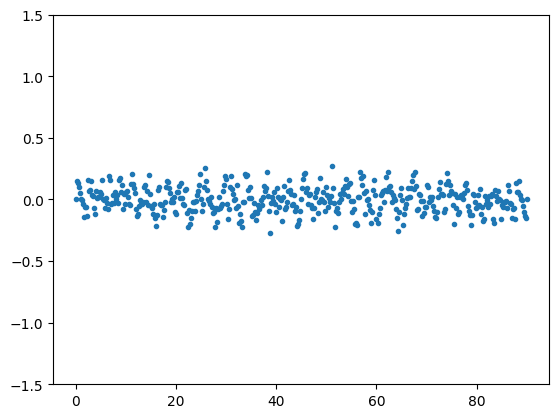

In [ ]:
print(np.average(tt_results)/(answer[0]))
print(np.std(tt_results)/np.average(tt_results))
print(np.average(td_results)/(answer[1]))
print(np.std(td_results)/np.average(td_results))
import matplotlib.pyplot as plt

#plt.plot(rotation_angles, rotation_angles)
plt.ylim(-1.5,1.5)
plt.plot(rotation_angles, theta_results-rotation_angles, '.')
thetaError = theta_results-rotation_angles
print(np.average(thetaError))
print(np.std(thetaError))

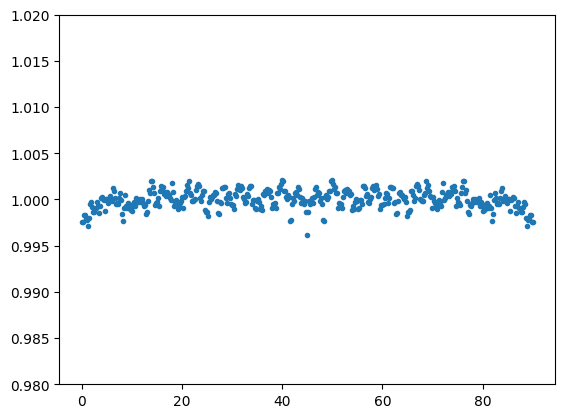

In [ ]:
plt.ylim(0.98, 1.02)
plt.plot(rotation_angles, tt_results/np.average(tt_results), '.')


In [ ]:
def objective_function(k_30, k_31, k_32, k_33, k_23, k_13):
    k_10 = 1
    #k_20 = 0
    #k_22 = 0
    # 1. Inside objective_function, construct the kernel_dmx matrix

    # 2. Inside objective_function, construct the kernel_dmx matrix

    kernel_dmx = np.array(
        [
            [k_33, k_23, k_13, 0, -k_13, -k_23, -k_33],
            [k_32, k_22, k_12, 0, -k_12, -k_22, -k_32],
            [k_31, k_21, k_11, 0, -k_11, -k_21, -k_31],
            [k_30, k_20, k_10, 0, -k_10, -k_20, -k_30],
            [k_31, k_21, k_11, 0, -k_11, -k_21, -k_31],
            [k_32, k_22, k_12, 0, -k_12, -k_22, -k_32],
            [k_33, k_23, k_13, 0, -k_13, -k_23, -k_33]
        ]
    )

    # 3. Initialize empty lists
    tt_results = []
    td_results = []
    theta_results = []

    # 4. Iterate through rotated_rectangle_arrays and rotation_angles
    for i, rotated_array in enumerate(trainingSet):
        # a. Call run_spin_simulation
        # The function run_spin_simulation returns 12 values, but we only need a few for the metrics
        finalTt, finalTd, finalTAngle, _, _, _, _, _, _, _, _, _ = run_spin_simulation(
            initial_array_2d=rotated_array,
            kernel_dmx=kernel_dmx,
            parameters=parameters
        )

        # b. Append the results
        tt_results.append(finalTt)
        td_results.append(finalTd)
        theta_results.append(finalTAngle)

    # 5. Calculate thetaError
    thetaError = np.array(theta_results) - rotation_angles

    # 6. Calculate the four target metrics:
    # a. metric_ta
    metric_tt = np.average(tt_results)
    metric_td = np.average(td_results)
    metric_ratio = metric_tt / metric_td * answer[1] / answer[0]

    metric_tt_std_avg = np.std(tt_results) / np.average(tt_results)

    metric_td_std_avg = np.std(td_results) / np.average(td_results)

    # c. metric_theta_avg_error
    metric_theta_avg_error = np.average(thetaError)

    # d. metric_theta_std_error
    metric_theta_std_error = np.std(thetaError)

    # 7. Calculate the combined scalar cost
    cost = (metric_ratio - 1)**2 + 100*(metric_tt_std_avg**2 + metric_td_std_avg**2) + 10*( metric_theta_avg_error**2 + metric_theta_std_error**2 )
    #cost = metric_tt_std_avg**2

    # 8. Return the calculated cost
    return cost

print("Objective function 'objective_function' defined.")

Objective function 'objective_function' defined.


In [ ]:
from scipy.optimize import minimize

# 1. Define an initial guess for a_d, d_d, and k_d
initial_guess = [0.2, 0.2, 0.2, 0.2, 0.2, 0.2] # Original values

# 2. Define bounds for a_d, d_d, and k_d
# Assuming these parameters should be non-negative and have reasonable upper limits
bounds = [  # a_d: must be positive, reasonable upper bound
    (-0.5, 1),  # d_d: must be positive, reasonable upper bound
    (-0.5, 1),   # k_d: must be positive, reasonable upper bound
    (-0.5, 1),
    (-0.5, 1),
    (-0.5, 1),
    (-0.5, 1)
]

# 3. Define a wrapper function for objective_function to accept a single array argument
def objective_function_wrapper(params):
    k_30, k_31, k_32, k_33, k_23, k_13 = params
    return objective_function(k_30, k_31, k_32, k_33, k_23, k_13)

# 4. Run the optimization
print("Starting optimization...")
result = minimize(
    objective_function_wrapper,
    initial_guess,
    bounds=bounds,
    method='L-BFGS-B' # A suitable method for bounded optimization
)

# 5. Extract optimized parameters
k_30, k_31, k_32, k_33, k_23, k_13 = result.x
print(result)
print(result.x)

Starting optimization...
  message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
  success: True
   status: 0
      fun: 0.10485553913553927
        x: [ 6.604e-02  1.617e-01  3.441e-01  1.224e-01  2.955e-02
             2.234e-01]
      nit: 15
      jac: [-2.127e-06  1.286e-06 -6.305e-06 -8.833e-06  1.818e-07
            -1.911e-06]
     nfev: 112
     njev: 16
 hess_inv: <6x6 LbfgsInvHessProduct with dtype=float64>
[0.06604264 0.16170641 0.34412011 0.12243503 0.02954822 0.22342547]


In [ ]:
kernel_dmx_7 = np.array([
            [k_33, k_23, k_13, 0, -k_13, -k_23, -k_33],
            [k_32, k_22, k_12, 0, -k_12, -k_22, -k_32],
            [k_31, k_21, k_11, 0, -k_11, -k_21, -k_31],
            [k_30, k_20, k_10, 0, -k_10, -k_20, -k_30],
            [k_31, k_21, k_11, 0, -k_11, -k_21, -k_31],
            [k_32, k_22, k_12, 0, -k_12, -k_22, -k_32],
            [k_33, k_23, k_13, 0, -k_13, -k_23, -k_33]
    ])

In [ ]:
print(kernel_dmx_7)

[[ 0.12243503  0.02954822  0.22342547  0.         -0.22342547 -0.02954822
  -0.12243503]
 [ 0.34412011  0.08973684  0.09205035  0.         -0.09205035 -0.08973684
  -0.34412011]
 [ 0.16170641  0.33693168  0.30414468  0.         -0.30414468 -0.33693168
  -0.16170641]
 [ 0.06604264  0.57063894  1.          0.         -1.         -0.57063894
  -0.06604264]
 [ 0.16170641  0.33693168  0.30414468  0.         -0.30414468 -0.33693168
  -0.16170641]
 [ 0.34412011  0.08973684  0.09205035  0.         -0.09205035 -0.08973684
  -0.34412011]
 [ 0.12243503  0.02954822  0.22342547  0.         -0.22342547 -0.02954822
  -0.12243503]]


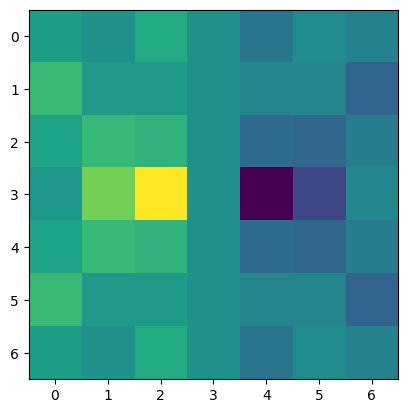

In [ ]:
plt.imshow(kernel_dmx_7)

In [ ]:
tt_results = []
td_results = []
theta_results = []

for i, rotated_array in enumerate(trainingSet):
    # Unpack the 8 return values from run_spin_simulation
    finalTot, finalTSum, finalTAngle, final_S_stacked, final_ET, final_EJ, Tfield, Ofield, Omag, Oangle, et_values, ej_values = run_spin_simulation(
        initial_array_2d=rotated_array,
        kernel_dmx = kernel_dmx_7,
        parameters = parameters
    )

    #print(f"Final Energy Sum: {finalTSum}")
    #print(f"Final Angle: {finalTAngle}")

    # The function now returns aggregated values for EJ, OX, OY, so no need for np.sum here.
    tt_results.append(finalTot)
    td_results.append(finalTSum)
    theta_results.append(finalTAngle)


59.87100013170452
0.0008691970387381784
59.98233111624133
0.0037579674871850073
-2.0417272208960196e-15
0.10166824078985828


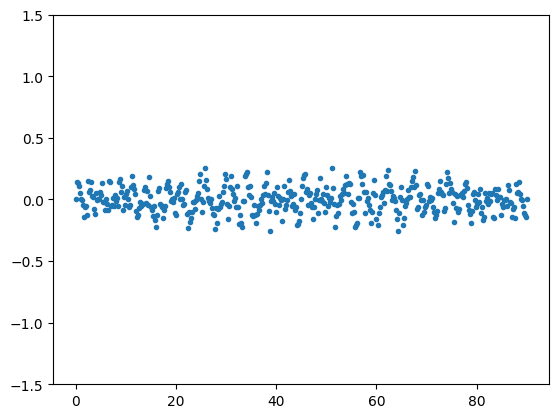

In [ ]:
print(np.average(tt_results)/(answer[0]))
print(np.std(tt_results)/np.average(tt_results))
print(np.average(td_results)/(answer[1]))
print(np.std(td_results)/np.average(td_results))
import matplotlib.pyplot as plt

plt.ylim(-1.5,1.5)
plt.plot(rotation_angles, theta_results-rotation_angles, '.')
thetaError = theta_results-rotation_angles
print(np.average(thetaError))
print(np.std(thetaError))

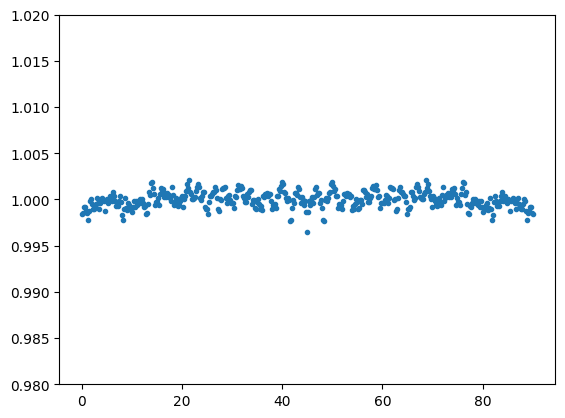

In [ ]:
plt.ylim(0.98, 1.02)
plt.plot(rotation_angles, tt_results/np.average(tt_results), '.')

In [ ]:
print(kernel_dmx_7)

[[ 0.12243503  0.02954822  0.22342547  0.         -0.22342547 -0.02954822
  -0.12243503]
 [ 0.34412011  0.08973684  0.09205035  0.         -0.09205035 -0.08973684
  -0.34412011]
 [ 0.16170641  0.33693168  0.30414468  0.         -0.30414468 -0.33693168
  -0.16170641]
 [ 0.06604264  0.57063894  1.          0.         -1.         -0.57063894
  -0.06604264]
 [ 0.16170641  0.33693168  0.30414468  0.         -0.30414468 -0.33693168
  -0.16170641]
 [ 0.34412011  0.08973684  0.09205035  0.         -0.09205035 -0.08973684
  -0.34412011]
 [ 0.12243503  0.02954822  0.22342547  0.         -0.22342547 -0.02954822
  -0.12243503]]
